###**Group:**
1. Suha Khalil
2. Sandra Igboabuchukwu
3. Noelle Haviland

##**Large Project 1**
##**Title:** Scalable Diabetes Risk Analytics & Classification using PySpark

##Runtime Calculation Notebook

###Preprocessing runtime:

In [1]:
#for colab
#!pip install pyspark


In [2]:
import sys
print(sys.executable)

c:\MyPython\python.exe


In [2]:
import os
import pyspark

SPARK_HOME = os.path.dirname(pyspark.__file__)
SPARK_CLASS = os.path.join(
    SPARK_HOME,
    "bin",
    "spark-class.cmd"
)
print("SPARK_HOME:", SPARK_HOME)
print("SPARK_CLASS:", SPARK_CLASS)
print("spark-class.cmd exists:",
      os.path.exists(SPARK_CLASS))


SPARK_HOME: c:\MyPython\lib\site-packages\pyspark
SPARK_CLASS: c:\MyPython\lib\site-packages\pyspark\bin\spark-class.cmd
spark-class.cmd exists: True


In [5]:


os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jdk-17"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["PATH"]

print("JAVA_HOME:", os.environ.get("JAVA_HOME"))

JAVA_HOME: C:\Program Files\Java\jdk-17


In [6]:
#Test Java calling :
import subprocess

print(subprocess.run(
    ["java", "-version"],
    capture_output=True,
    text=True
).stderr)

java version "17.0.12" 2024-07-16 LTS
Java(TM) SE Runtime Environment (build 17.0.12+8-LTS-286)
Java HotSpot(TM) 64-Bit Server VM (build 17.0.12+8-LTS-286, mixed mode, sharing)



In [7]:
#test java jdk
print(subprocess.run(
    ["jps"],
    capture_output=True,
    text=True
).stdout)

30184 Jps



In [8]:
#Import Libraries
import pyspark
import requests
from pyspark.sql import SparkSession

from pyspark.sql.functions import (
    col,
    sum,
    min,
    max,
    count,
    round as spark_round
)

from pyspark.ml.feature import VectorAssembler, StandardScaler

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import time
import os
import psutil
import urllib.request

In [9]:
# For Suha's copy On Colab

#print("Available CPU cores:", os.cpu_count())

#print(
   # "Total RAM (GB):",
    #round(psutil.virtual_memory().total / (1024**3), 2)
#)

In [ ]:
# ForSuha's copy on VS code

print("Logical CPUs:", os.cpu_count())
print("Total RAM GB:", round(psutil.virtual_memory().total / (1024**3), 2))

Logical CPUs: 20
RAM GB: 31.71


In [11]:
# Download once before benchmarking


github_url = "https://raw.githubusercontent.com/sykhalil/Big_Data_Analytics_SAT5165_Projects/refs/heads/main/Large_Project_1/diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

file_path = "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

urllib.request.urlretrieve(github_url, file_path)

('diabetes_binary_5050split_health_indicators_BRFSS2015.csv',
 <http.client.HTTPMessage at 0x216d136d880>)

In [12]:
#for running in Colab

#SPARK_HOME = "/usr/local/lib/python3.13/dist-packages/pyspark"
#SPARK_CLASS = f"{SPARK_HOME}/bin/spark-class"

#print("spark-class exists:", os.path.exists(SPARK_CLASS))

In [13]:
#start the Spark Master

import subprocess
import time

master_process = subprocess.Popen(
    [
        SPARK_CLASS,
        "org.apache.spark.deploy.master.Master",
        "--host", "127.0.0.1",
        "--port", "7077",
        "--webui-port", "8080"
    ]
)

time.sleep(3)

print("Master running:", master_process.poll() is None)

Master running: True


In [14]:
#start 1 worker with one core
worker_process = subprocess.Popen(
    [
        SPARK_CLASS,
        "org.apache.spark.deploy.worker.Worker",
        "--cores", "1",
        "--memory", "2G",
        "--webui-port", "8081",
        "spark://127.0.0.1:7077"
    ]
)

time.sleep(3)

print("Worker running:", worker_process.poll() is None)

Worker running: True


In [15]:
import subprocess

JPS = r"C:\Program Files\Java\jdk-17\bin\jps.exe"

result = subprocess.run(
    [JPS],
    capture_output=True,
    text=True
)

print(result.stdout)

38864 Jps
19084 Worker
23356 Master



In [ ]:
#connect to master /worker
spark = (
    SparkSession.builder
    .appName("DiabetesPreprocessingBenchmark")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .config("spark.cores.max", "1")
    .getOrCreate()
)
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Executor cores:",
      spark.sparkContext.getConf().get("spark.executor.cores"))

print("Maximum cores:",
      spark.sparkContext.getConf().get("spark.cores.max"))

Spark version: 4.0.5
Spark master: spark://127.0.0.1:7077


In [17]:
#verify if the standalone setup is active
print("Spark master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)
print("Application ID:", spark.sparkContext.applicationId)

Spark master: spark://127.0.0.1:7077
Default parallelism: 2
Application ID: app-20261028232031-0000


In [ ]:

print("Application name:", spark.sparkContext.appName)

Spark version: 4.0.5
Application name: DiabetesPreprocessingBenchmark


### **Performance Scaling Experiment**

Each team member will run and time their complete assigned Spark workload using:

**1** executor with 1 core

**2** executors with 1 core each

**4** executors with 1 core each

Each configuration will be repeated at least 3 times.

For each run, we will record:
- Wall-clock runtime
- Number of executors
- Number of partitions
- CPU count
- Available RAM

The mean runtime and standard deviation will be calculated for each configuration.

Speedup will be calculated as:

**Speedup = $T_1 / T_n$**

where $T_1$ is the mean runtime with 1 executor and $T_n$ is the mean runtime with n executors.

### **The preprocessing time excluding side processes like show() and plot**


In [19]:
#verification before running the warmup
result = subprocess.run(
    [r"C:\Program Files\Java\jdk-17\bin\jps.exe"],
    capture_output=True,
    text=True
)

print(result.stdout)

13040 Jps
39520 SparkSubmit
22020 CoarseGrainedExecutorBackend
19084 Worker
23356 Master



In [20]:
# in this cell, I will create a function that has
#  the Benchmark one complete preprocessing run
# so I can use it later 

def run_preprocessing_benchmark(num_executors):

    spark.catalog.clearCache()

    start_time = time.perf_counter()

    # 1. Load dataset
    #file_path = "/content/diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

    benchmark_df = spark.read.csv(
        file_path,
        header=True,
        inferSchema=True
    ).repartition(8)

    # Record number of partitions
    num_partitions = benchmark_df.rdd.getNumPartitions()

    # 2. Validate dimensions
    row_count = benchmark_df.count()
    column_count = len(benchmark_df.columns)

    # 3. Check missing values
    null_counts = benchmark_df.select([
        sum(col(c).isNull().cast("int")).alias(c)
        for c in benchmark_df.columns
    ])

    null_counts.collect()

    # 4. Check duplicate rows
    distinct_rows = benchmark_df.distinct().count()
    duplicate_rows = row_count - distinct_rows

    # 5. Define target and predictors
    label_col = "Diabetes_binary"

    feature_cols = [
        c for c in benchmark_df.columns
        if c != label_col
    ]

    # 6. Split data
    benchmark_train, benchmark_test = benchmark_df.randomSplit(
        [0.8, 0.2],
        seed=42
    )

    # 7. Assemble features
    benchmark_assembler = VectorAssembler(
        inputCols=feature_cols,
        outputCol="features"
    )

    benchmark_train_assembled = benchmark_assembler.transform(
        benchmark_train
    )

    benchmark_test_assembled = benchmark_assembler.transform(
        benchmark_test
    )

    # 8. Fit StandardScaler
    benchmark_scaler = StandardScaler(
        inputCol="features",
        outputCol="scaledFeatures",
        withStd=True,
        withMean=False
    )

    benchmark_scaler_model = benchmark_scaler.fit(
        benchmark_train_assembled
    )

    # 9. Apply scaler
    benchmark_train_scaled = benchmark_scaler_model.transform(
        benchmark_train_assembled
    )

    benchmark_test_scaled = benchmark_scaler_model.transform(
        benchmark_test_assembled
    )

    # Force Spark execution
    train_rows = benchmark_train_scaled.count()
    test_rows = benchmark_test_scaled.count()

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    # System information
    cpu_count = os.cpu_count()
    available_ram_gb = psutil.virtual_memory().available / (1024**3)

    return {
        "Executors": num_executors,
        "Runtime_seconds": elapsed_time,
        "Partitions": num_partitions,
        "CPU_count": cpu_count,
        "Available_RAM_GB": available_ram_gb
    }

In [21]:
warmup_1 = run_preprocessing_benchmark(num_executors=1)

In [22]:
results_1_executor = []

for run in range(1, 4):

    result = run_preprocessing_benchmark(num_executors=1)

    result["Run"] = run
    results_1_executor.append(result)

    print(
        f"Run {run}: "
        f"{result['Runtime_seconds']:.3f} seconds"
    )

Run 1: 15.411 seconds
Run 2: 14.743 seconds
Run 3: 15.005 seconds


In [23]:
#Create a table for the results

results_1_df = pd.DataFrame(results_1_executor)

results_1_df = results_1_df[
    [
        "Run",
        "Executors",
        "Runtime_seconds",
        "Partitions",
        "CPU_count",
        "Available_RAM_GB"
    ]
]

results_1_df

,Run,Executors,Runtime_seconds,Partitions,CPU_count,Available_RAM_GB
0,1,1,15.410951,8,20,13.817711
1,2,1,14.742853,8,20,13.722424
2,3,1,15.004741,8,20,13.437943


In [24]:
mean_runtime_1 = results_1_df["Runtime_seconds"].mean()
std_runtime_1 = results_1_df["Runtime_seconds"].std()

print(f"Mean runtime: {mean_runtime_1:.3f} seconds")
print(f"Standard deviation: {std_runtime_1:.3f} seconds")

Mean runtime: 15.053 seconds
Standard deviation: 0.337 seconds


##Repeat the experiment with two executors, 1 core each , but first we should stop the current spark application with 1 executor.

In [25]:
#stop spark application
try:
    spark.stop()
    print("Spark application stopped.")
except Exception as e:
    print("No active Spark application or it was already stopped.")

Spark application stopped.


In [26]:
# this is a cleanup loop that makes sure the old master and worker are stopped

import subprocess
import os
import signal
import time

result = subprocess.run(
    [r"C:\Program Files\Java\jdk-17\bin\jps.exe"],
    capture_output=True,
    text=True
)

print(result.stdout)

print("Before cleanup:")
print(result.stdout)

for line in result.stdout.strip().splitlines():
    parts = line.split()

    # Skip warning lines or anything that does not start with a numeric PID
    if len(parts) >= 2 and parts[0].isdigit():

        pid = int(parts[0])
        process_name = parts[1]

        if process_name in ["Master", "Worker"]:
            print(f"Stopping {process_name} PID {pid}")
            os.kill(pid, signal.SIGTERM)

time.sleep(3)

20464 Jps
39520 SparkSubmit
19084 Worker
23356 Master

Before cleanup:
20464 Jps
39520 SparkSubmit
19084 Worker
23356 Master

Stopping Worker PID 19084
Stopping Master PID 23356


In [27]:
#make sure they stopped :

result = subprocess.run(
    [r"C:\Program Files\Java\jdk-17\bin\jps.exe"],
    capture_output=True,
    text=True
)

print(result.stdout)

39520 SparkSubmit
11684 Jps



In [28]:
# Start a fresh Spark Master for the 2-executor experiment

master_process = subprocess.Popen(
    [
        SPARK_CLASS,
        "org.apache.spark.deploy.master.Master",
        "--host", "127.0.0.1",
        "--port", "7077",
        "--webui-port", "8080"
    ]
)

time.sleep(3)

print("Master process running:", master_process.poll() is None)

Master process running: True


In [29]:
# Start 2 Spark workers, each with 1 core

#create an empty list to save the workers after we create them
worker_processes = []

#create workers, I assigned a different port number for each worker :
for i in range(2):
    worker = subprocess.Popen(
        [
            SPARK_CLASS,
            "org.apache.spark.deploy.worker.Worker",
            "--cores", "1",
            "--memory", "2G",
            "--webui-port", str(8081 + i),
            "spark://127.0.0.1:7077"
        ]
    )

    worker_processes.append(worker)

time.sleep(4)

for i, worker in enumerate(worker_processes, start=1):
    print(f"Worker {i} running:", worker.poll() is None)

Worker 1 running: True
Worker 2 running: True


In [30]:
#verify before connection :
#Verify the Java Process :
time.sleep(5)

result = subprocess.run(
    [r"C:\Program Files\Java\jdk-17\bin\jps.exe"],
    capture_output=True,
    text=True
)

print(result.stdout)

39520 SparkSubmit
24788 Worker
40052 Jps
14184 Worker
16872 Master



In [31]:
# reconnect Spark application to use these two 1-core workers we created :
spark = (
    SparkSession.builder
    .appName("DiabetesPreprocessingBenchmark")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .config("spark.cores.max", "2")
    .getOrCreate()
)
print("Spark master:", spark.sparkContext.master)
print("Application ID:", spark.sparkContext.applicationId)

Spark master: spark://127.0.0.1:7077
Application ID: app-20261028232216-0000


In [32]:
#verify after connection :
#Verify the Java Process :
time.sleep(5)

result = subprocess.run(
    [r"C:\Program Files\Java\jdk-17\bin\jps.exe"],
    capture_output=True,
    text=True
)

print(result.stdout)

39520 SparkSubmit
23060 CoarseGrainedExecutorBackend
24788 Worker
14184 Worker
16872 Master
40952 Jps
11324 CoarseGrainedExecutorBackend



In [33]:
warmup_2 = run_preprocessing_benchmark(num_executors=2)

print(f"2-executor warm-up runtime: {warmup_2['Runtime_seconds']:.3f} seconds")

2-executor warm-up runtime: 43.206 seconds


In [34]:
results_2_executor = []

for run in range(1, 4):

    result = run_preprocessing_benchmark(num_executors=2)

    result["Run"] = run
    results_2_executor.append(result)

    print(
        f"Run {run}: "
        f"{result['Runtime_seconds']:.3f} seconds"
    )

Run 1: 11.967 seconds
Run 2: 11.802 seconds
Run 3: 13.486 seconds


In [35]:
results_2_df = pd.DataFrame(results_2_executor)

results_2_df = results_2_df[
    [
        "Run",
        "Executors",
        "Runtime_seconds",
        "Partitions",
        "CPU_count",
        "Available_RAM_GB"
    ]
]

results_2_df

,Run,Executors,Runtime_seconds,Partitions,CPU_count,Available_RAM_GB
0,1,2,11.967259,8,20,13.157116
1,2,2,11.801533,8,20,13.122475
2,3,2,13.486154,8,20,13.195122


In [36]:
mean_runtime_2 = results_2_df["Runtime_seconds"].mean()
std_runtime_2 = results_2_df["Runtime_seconds"].std()

print(f"Mean runtime: {mean_runtime_2:.3f} seconds")
print(f"Standard deviation: {std_runtime_2:.3f} seconds")

Mean runtime: 12.418 seconds
Standard deviation: 0.928 seconds


In [37]:
#before I move to 4 executors, I will compare the two experiemnes with 1 and 2 executors

comparison_df = pd.DataFrame({
    "Executors": [1, 2],
    "Mean_Runtime_s": [
        results_1_df["Runtime_seconds"].mean(),
        results_2_df["Runtime_seconds"].mean()
    ],
    "Std_Runtime_s": [
        results_1_df["Runtime_seconds"].std(),
        results_2_df["Runtime_seconds"].std()
    ]
})

comparison_df["Speedup"] = (
    comparison_df.loc[comparison_df["Executors"] == 1, "Mean_Runtime_s"].iloc[0]
    / comparison_df["Mean_Runtime_s"]
)

comparison_df

,Executors,Mean_Runtime_s,Std_Runtime_s,Speedup
0,1,15.052848,0.336637,1.000000
1,2,12.418315,0.928481,1.212149


### Runtime plot

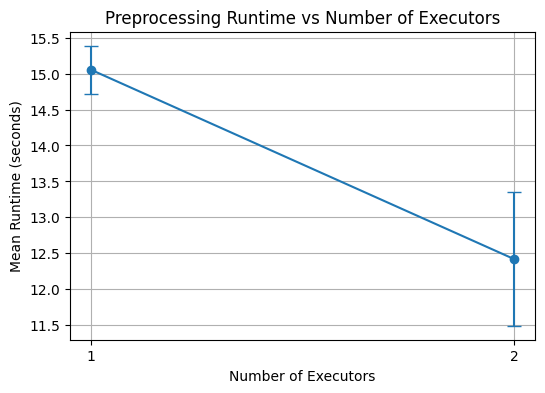

In [38]:
plt.figure(figsize=(6,4))

plt.errorbar(
    comparison_df["Executors"],
    comparison_df["Mean_Runtime_s"],
    yerr=comparison_df["Std_Runtime_s"],
    marker="o",
    capsize=5
)

plt.xlabel("Number of Executors")
plt.ylabel("Mean Runtime (seconds)")
plt.title("Preprocessing Runtime vs Number of Executors")
plt.xticks([1, 2])
plt.grid(True)
plt.show()

### Speed up plot

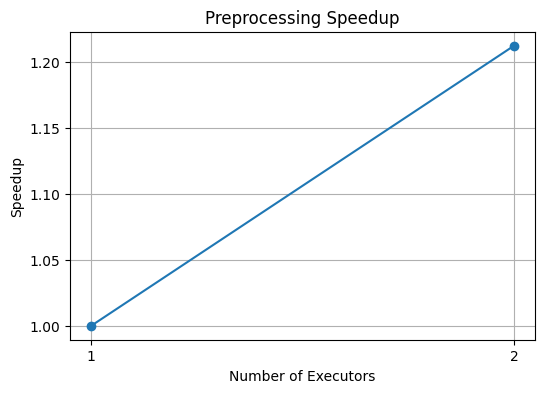

In [39]:
plt.figure(figsize=(6,4))

plt.plot(
    comparison_df["Executors"],
    comparison_df["Speedup"],
    marker="o"
)

plt.xlabel("Number of Executors")
plt.ylabel("Speedup")
plt.title("Preprocessing Speedup")
plt.xticks([1, 2])
plt.grid(True)
plt.show()

The 2-executor configuration improved preprocessing performance. Its mean runtime was lower than the 1-executor configuration, producing a speedup of 20%. 

## Experiment of 4 executors :

In [40]:
#cleanup the previous:

try:
    spark.stop()
    print("Spark application stopped.")
except:
    print("No active Spark application.")

Spark application stopped.


In [41]:
#Stop previous masters and workers :

result = subprocess.run(
    [r"C:\Program Files\Java\jdk-17\bin\jps.exe"],
    capture_output=True,
    text=True
)

print(result.stdout)

for line in result.stdout.strip().splitlines():
    parts = line.split()

    if len(parts) >= 2 and parts[0].isdigit():
        pid = int(parts[0])
        process_name = parts[1]

        if process_name in ["Master", "Worker"]:
            print(f"Stopping {process_name} PID {pid}")
            os.kill(pid, signal.SIGTERM)

time.sleep(3)

39520 SparkSubmit
24788 Worker
32692 Jps
14184 Worker
16872 Master

Stopping Worker PID 24788
Stopping Worker PID 14184
Stopping Master PID 16872


In [42]:
#Verify that we have no active masters or workers :

result = subprocess.run(
    [r"C:\Program Files\Java\jdk-17\bin\jps.exe"],
    capture_output=True,
    text=True
)

print(result.stdout)

39520 SparkSubmit
18412 Jps



In [43]:
#Start a new fresh master
master_process = subprocess.Popen(
    [
        SPARK_CLASS,
        "org.apache.spark.deploy.master.Master",
        "--host", "127.0.0.1",
        "--port", "7077",
        "--webui-port", "8080"
    ]
)

time.sleep(3)

print("Master process running:", master_process.poll() is None)

Master process running: True


In [44]:
# start 1-core 4 workers
worker_processes = []

for i in range(4):
    worker = subprocess.Popen(
        [
            SPARK_CLASS,
            "org.apache.spark.deploy.worker.Worker",
            "--cores", "1",
            "--memory", "2G",
            "--webui-port", str(8081 + i),
            "spark://127.0.0.1:7077"
        ]
    )

    worker_processes.append(worker)

time.sleep(4)

for i, worker in enumerate(worker_processes, start=1):
    print(f"Worker {i} running:", worker.poll() is None)

Worker 1 running: True
Worker 2 running: True
Worker 3 running: True
Worker 4 running: True


In [45]:
spark = (
    SparkSession.builder
    .appName("DiabetesPreprocessingBenchmark")
    .master("spark://127.0.0.1:7077")
    .config("spark.executor.cores", "1")
    .config("spark.cores.max", "4")
    .getOrCreate()
)

In [46]:

result = subprocess.run(
    [r"C:\Program Files\Java\jdk-17\bin\jps.exe"],
    capture_output=True,
    text=True
)

print(result.stdout)

28032 Worker
39520 SparkSubmit
30308 Master
38564 Jps
11688 Worker
6776 Worker
32972 Worker



In [47]:
# the warmup run for four workers :
warmup_4 = run_preprocessing_benchmark(num_executors=4)

print(f"4-executor warm-up runtime: {warmup_4['Runtime_seconds']:.3f} seconds")

4-executor warm-up runtime: 56.005 seconds


In [48]:
# Repeat the execution Three times:
results_4_executor = []

for run in range(1, 4):
    result = run_preprocessing_benchmark(num_executors=4)

    result["Run"] = run
    results_4_executor.append(result)

    print(f"Run {run}: {result['Runtime_seconds']:.3f} seconds")

Run 1: 14.169 seconds
Run 2: 11.747 seconds
Run 3: 10.901 seconds


In [49]:
#save the results into a dataframe
results_4_df = pd.DataFrame(results_4_executor)[
    ["Run", "Executors", "Runtime_seconds", "Partitions", "CPU_count", "Available_RAM_GB"]
]

mean_runtime_4 = results_4_df["Runtime_seconds"].mean()
std_runtime_4 = results_4_df["Runtime_seconds"].std()

print(results_4_df)
print(f"\nMean runtime: {mean_runtime_4:.3f} seconds")
print(f"Standard deviation: {std_runtime_4:.3f} seconds")

   Run  Executors  Runtime_seconds  Partitions  CPU_count  Available_RAM_GB
0    1          4        14.168899           8         20         11.932659
1    2          4        11.747309           8         20         11.879982
2    3          4        10.901110           8         20         11.887127

Mean runtime: 12.272 seconds
Standard deviation: 1.696 seconds


In [50]:
## Comparison :

comparison_df = pd.DataFrame({
    "Executors": [1, 2, 4],
    "Mean_Runtime_s": [
        results_1_df["Runtime_seconds"].mean(),
        results_2_df["Runtime_seconds"].mean(),
        results_4_df["Runtime_seconds"].mean()
    ],
    "Std_Runtime_s": [
        results_1_df["Runtime_seconds"].std(),
        results_2_df["Runtime_seconds"].std(),
        results_4_df["Runtime_seconds"].std()
    ]
})

# Speedup relative to 1 executor
t1 = comparison_df.loc[
    comparison_df["Executors"] == 1,
    "Mean_Runtime_s"
].iloc[0]

comparison_df["Speedup"] = t1 / comparison_df["Mean_Runtime_s"]

comparison_df

,Executors,Mean_Runtime_s,Std_Runtime_s,Speedup
0,1,15.052848,0.336637,1.000000
1,2,12.418315,0.928481,1.212149
2,4,12.272439,1.696005,1.226557


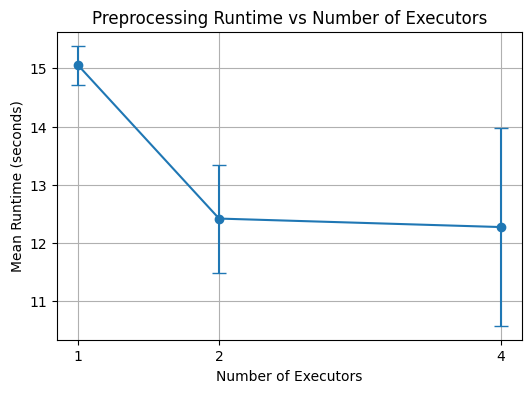

In [51]:
# Plot runtime with Error bars

plt.figure(figsize=(6, 4))

plt.errorbar(
    comparison_df["Executors"],
    comparison_df["Mean_Runtime_s"],
    yerr=comparison_df["Std_Runtime_s"],
    marker="o",
    capsize=5
)

plt.xlabel("Number of Executors")
plt.ylabel("Mean Runtime (seconds)")
plt.title("Preprocessing Runtime vs Number of Executors")
plt.xticks([1, 2, 4])
plt.grid(True)

plt.show()

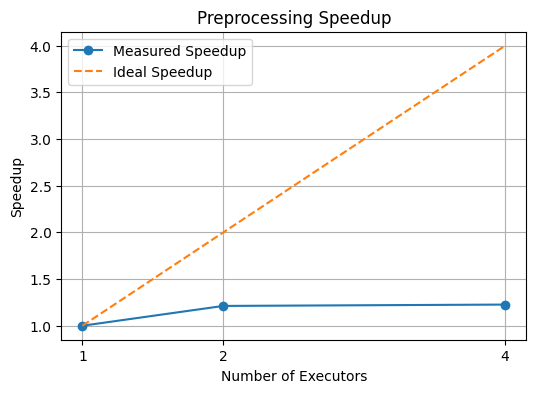

In [52]:
#the speedup plot

plt.figure(figsize=(6, 4))

plt.plot(
    comparison_df["Executors"],
    comparison_df["Speedup"],
    marker="o",
    label="Measured Speedup"
)

plt.plot(
    [1, 2, 4],
    [1, 2, 4],
    linestyle="--",
    label="Ideal Speedup"
)

plt.xlabel("Number of Executors")
plt.ylabel("Speedup")
plt.title("Preprocessing Speedup")
plt.xticks([1, 2, 4])
plt.grid(True)
plt.legend()

plt.show()

We can see that using 4 executors was still in the range of 20% speedup performance compared to the 1- executor, but the improvement compared to 2 executors was slightly negligible , this is because the dataset is only about 70K datapoint, and the process we are testing is simple preprocessing, it seems that two executors are more than enough for it. 